In [ ]:
# Activity 2: House Price Prediction using Linear Regression

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Load dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

First five rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [9]:
# Input feature
X = df[["MedInc"]]

# Target variable
y = df["MedHouseVal"]

print("Input feature: Median Income")
print("Target variable: Median House Value")

Input feature: Median Income
Target variable: Median House Value


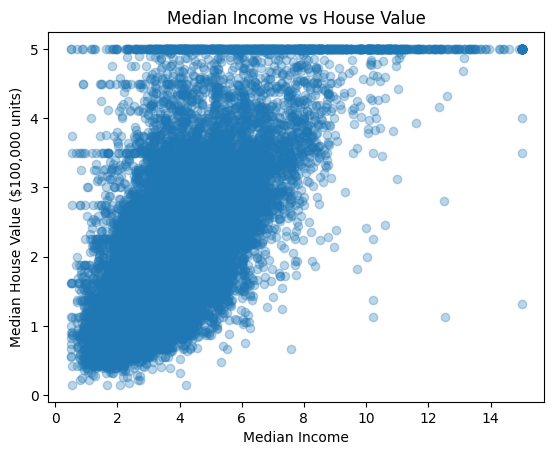

In [10]:
plt.scatter(X["MedInc"], y, alpha=0.3)

plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value ($100,000 units)")

plt.show()

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 16512
Testing records: 4128


In [12]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

print(
    "Equation: House Value =",
    model.coef_[0], "* Median Income +",
    model.intercept_
)

Coefficient: 0.4193384939381271
Intercept: 0.4445972916907879
Equation: House Value = 0.4193384939381271 * Median Income + 0.4445972916907879


In [13]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred[:10]
})

print(comparison)

   Actual Price  Predicted Price
0       0.47700         1.149589
1       0.45800         1.506069
2       5.00001         1.903937
3       2.18600         2.850594
4       2.78000         2.006633
5       1.58700         2.421652
6       1.98200         2.576472
7       1.57500         1.992292
8       3.40000         2.458932
9       4.46600         3.846774


In [14]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.629908653009376
MSE: 0.7091157771765549
RMSE: 0.8420901241414455
R2 Score: 0.45885918903846656


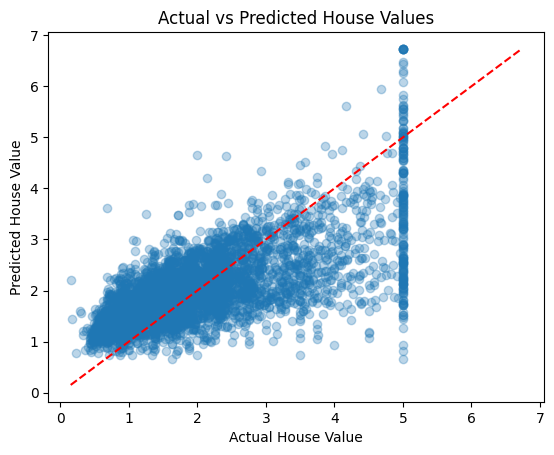

In [15]:
plt.scatter(y_test, y_pred, alpha=0.3)

# Reference line for perfect predictions
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")

plt.show()

In [16]:
# Example: median income value of 5
new_data = pd.DataFrame({"MedInc": [5.0]})

predicted_value = model.predict(new_data)[0]

print("Median Income:", 5.0)
print(
    "Predicted House Value:",
    round(predicted_value, 3),
    "in units of $100,000"
)
print(
    "Approximate value in dollars:",
    round(predicted_value * 100000, 2)
)

Median Income: 5.0
Predicted House Value: 2.541 in units of $100,000
Approximate value in dollars: 254128.98
